In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.sparse import issparse
from scipy.stats import mannwhitneyu
import scanpy as sc
import tqdm
import functools
import glob
import gzip as gz
import itertools
import math
import os
import sys
from importlib import reload

sys.path.append('/Genomics/pritykinlab/dillon/perturbseq/scripts/utils')
import misc
import clonal_processing

In [2]:
plt.rcParams["axes.titlesize"] = 25
plt.rcParams["axes.labelsize"] = 25
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20
plt.rcParams["lines.markersize"] = 5
plt.rcParams['axes.grid'] = False
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['ytick.major.size'] = 5
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.title_fontsize'] = 15
plt.rcParams['legend.edgecolor'] = 'dimgray'
plt.rcParams['figure.figsize'] = (7,7)

In [3]:
reload(misc)

<module 'misc' from '/Genomics/pritykinlab/dillon/perturbseq/scripts/utils/misc.py'>

# Initial Processing

In [4]:
# Jupyter Notebook cell

# 1) Define the base directory and lanes
base_dir = "/Genomics/pritykinlab/share/perturbseq/fromMarc/new_data/trim28_setdb1_data/analysis"
lanes = [f"Lane{n}" for n in range(1, 17)]

# 2) Load each lane's data into an OrderedDict of AnnData
adata_dict = misc.load_adata_dict(
    base_dir=base_dir,
    lane_list=lanes,
    filename="filtered_feature_bc_matrix.h5",  # typical Cell Ranger output
    mito_prefix="mt-"                          # typical for mouse data
)

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_

##### Lane: Lane1 #####


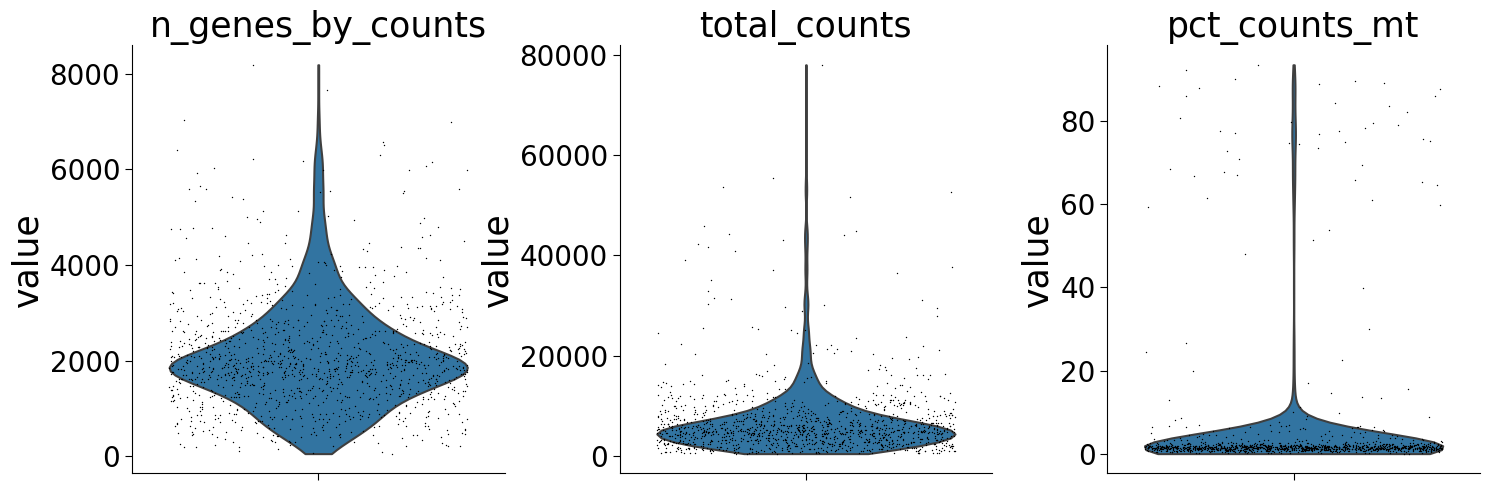

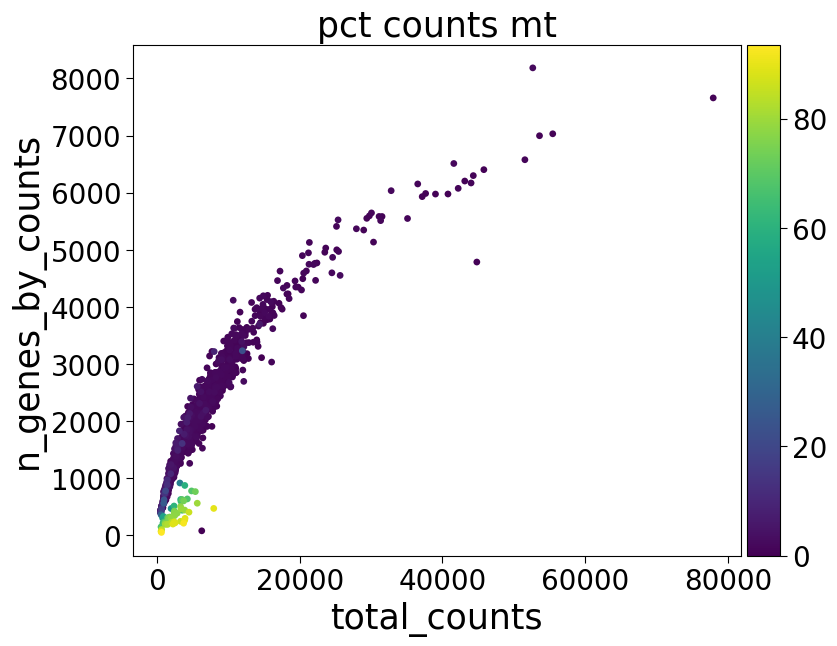

##### Lane: Lane2 #####


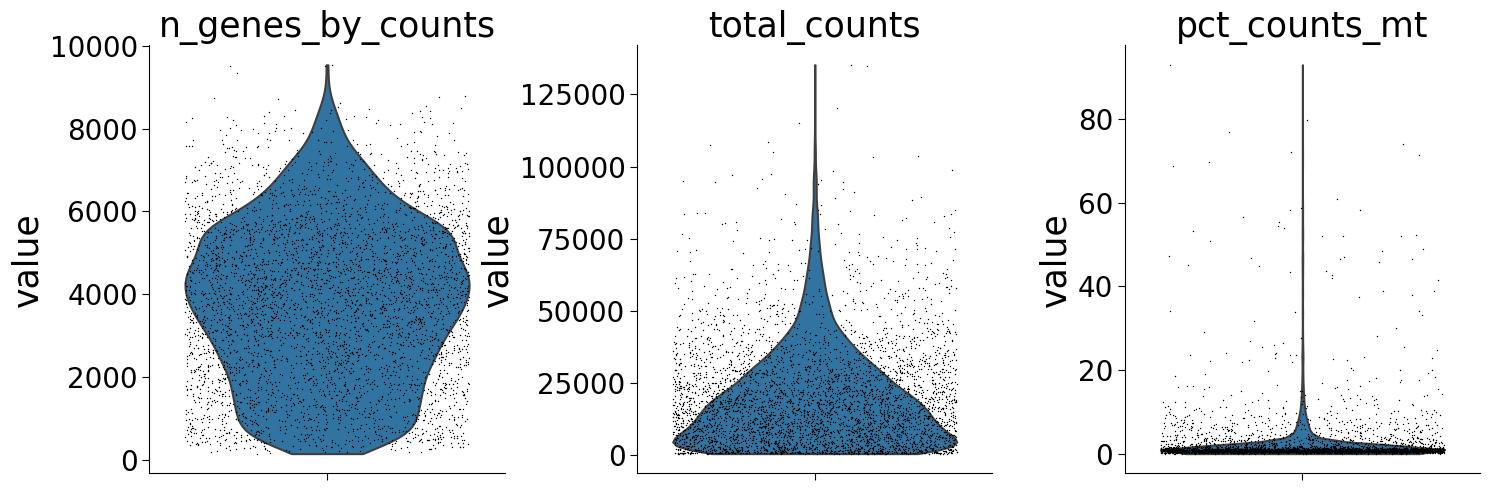

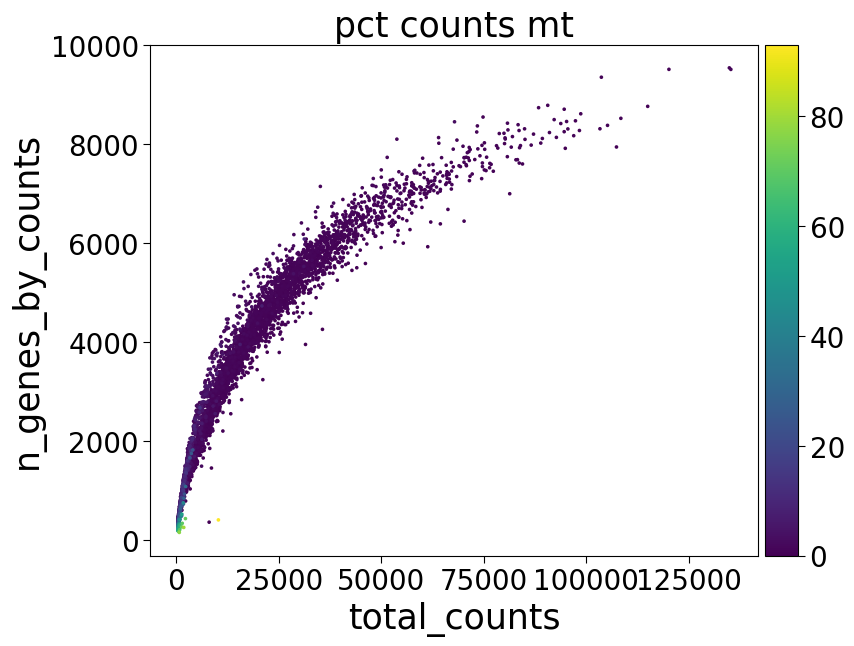

##### Lane: Lane3 #####


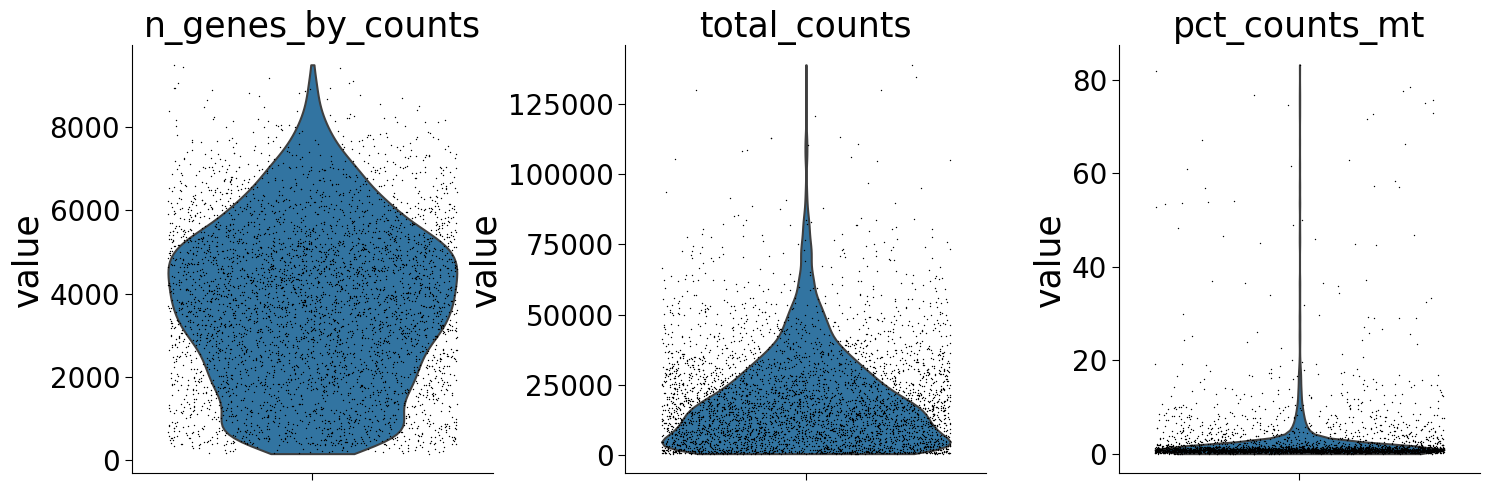

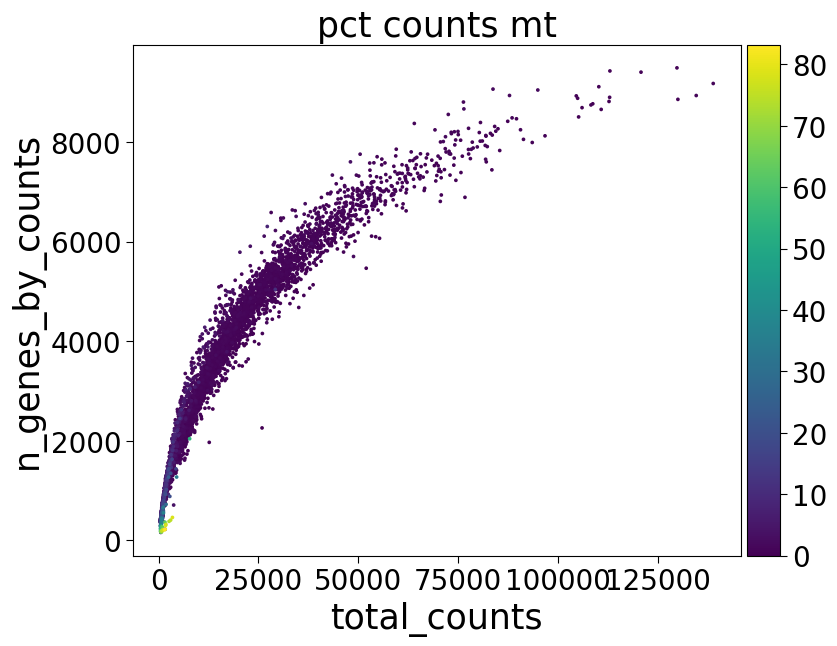

##### Lane: Lane4 #####


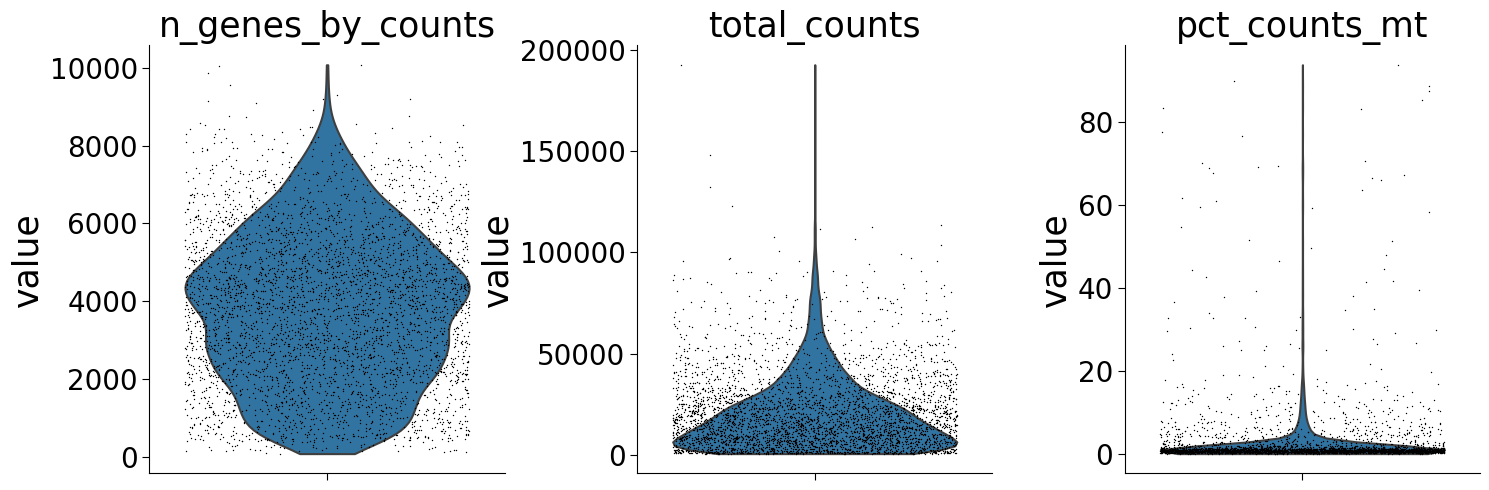

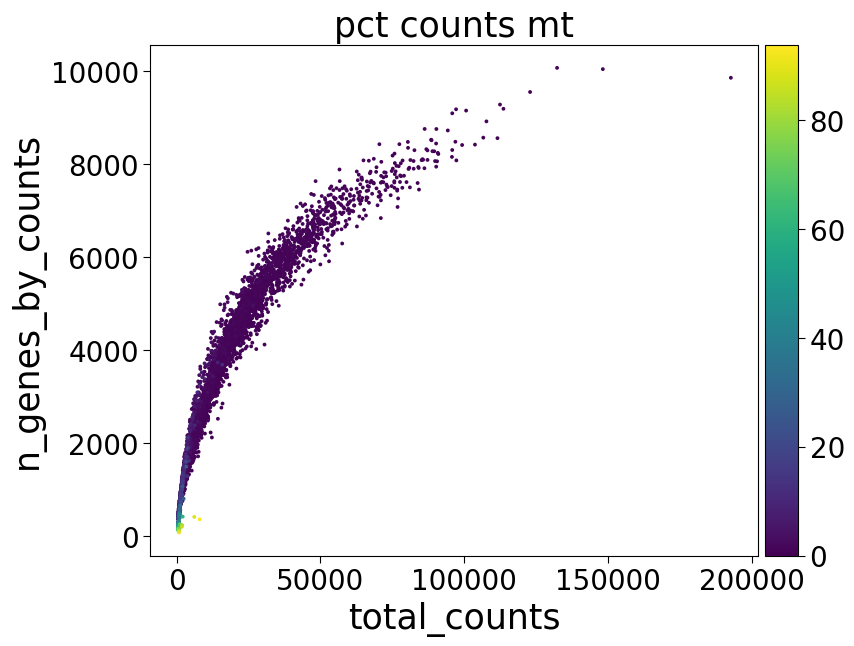

##### Lane: Lane5 #####


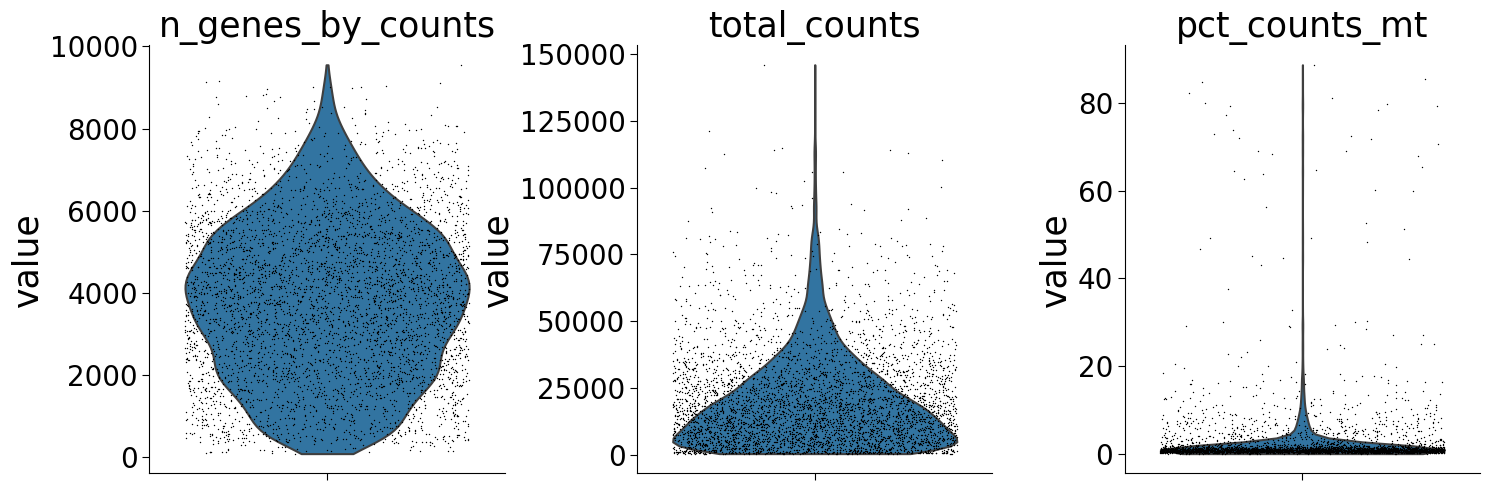

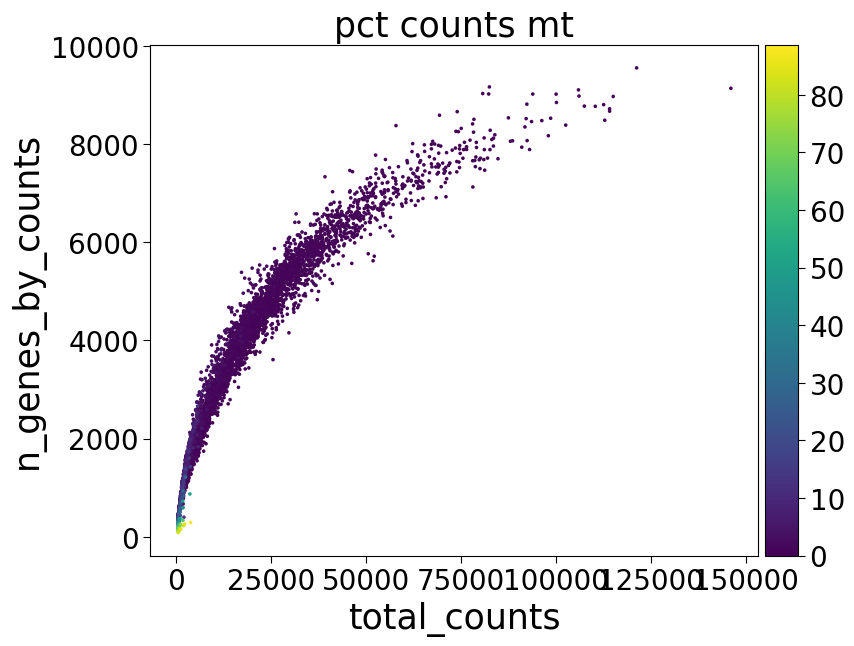

##### Lane: Lane6 #####


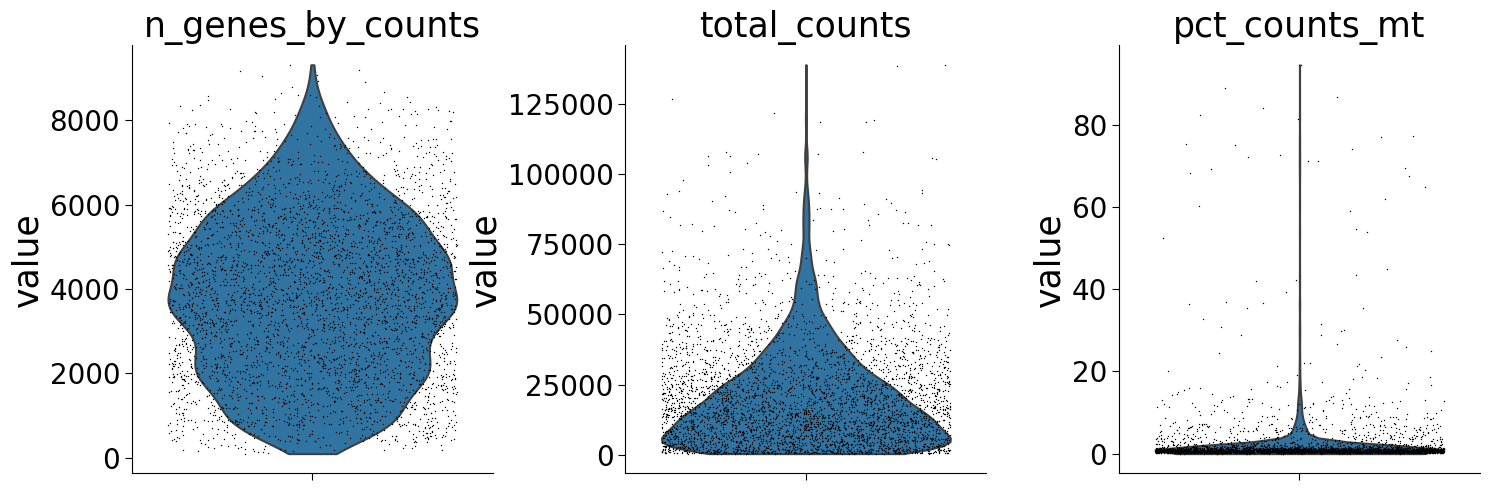

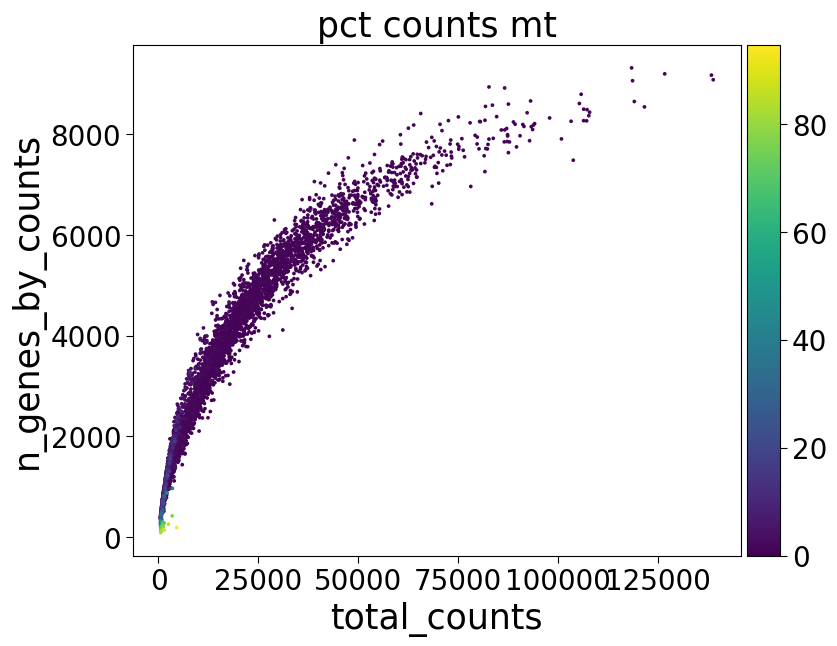

##### Lane: Lane7 #####


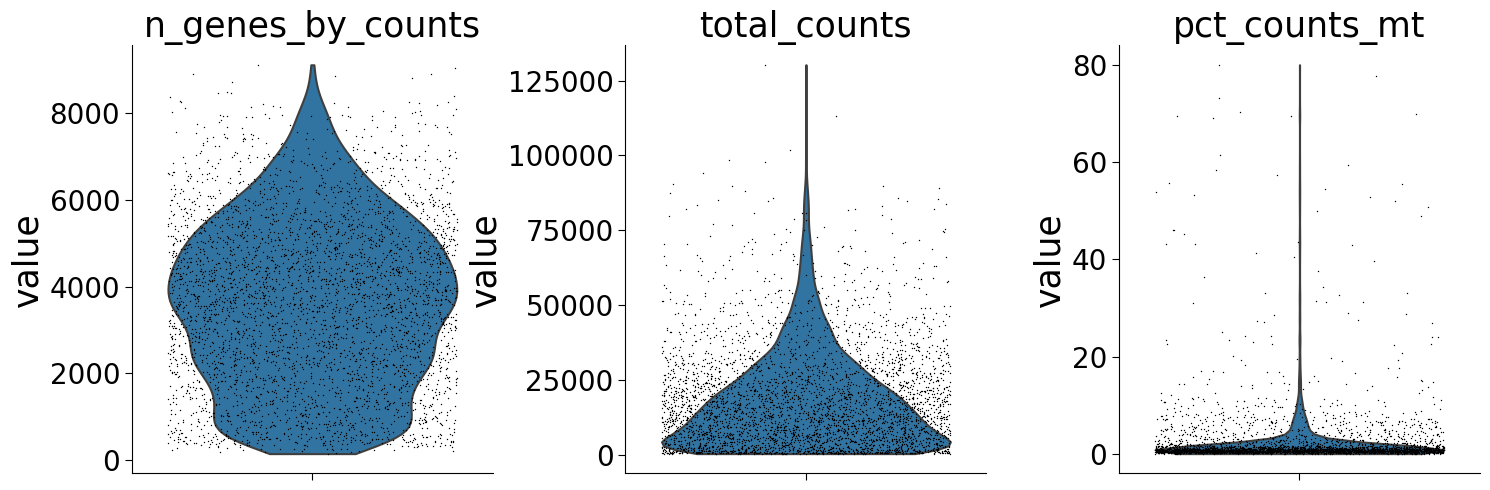

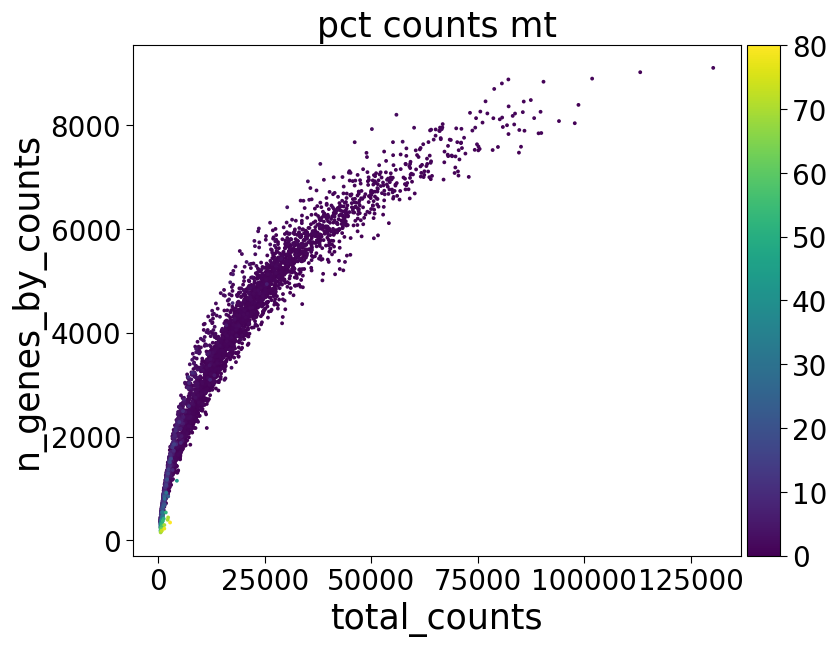

##### Lane: Lane8 #####


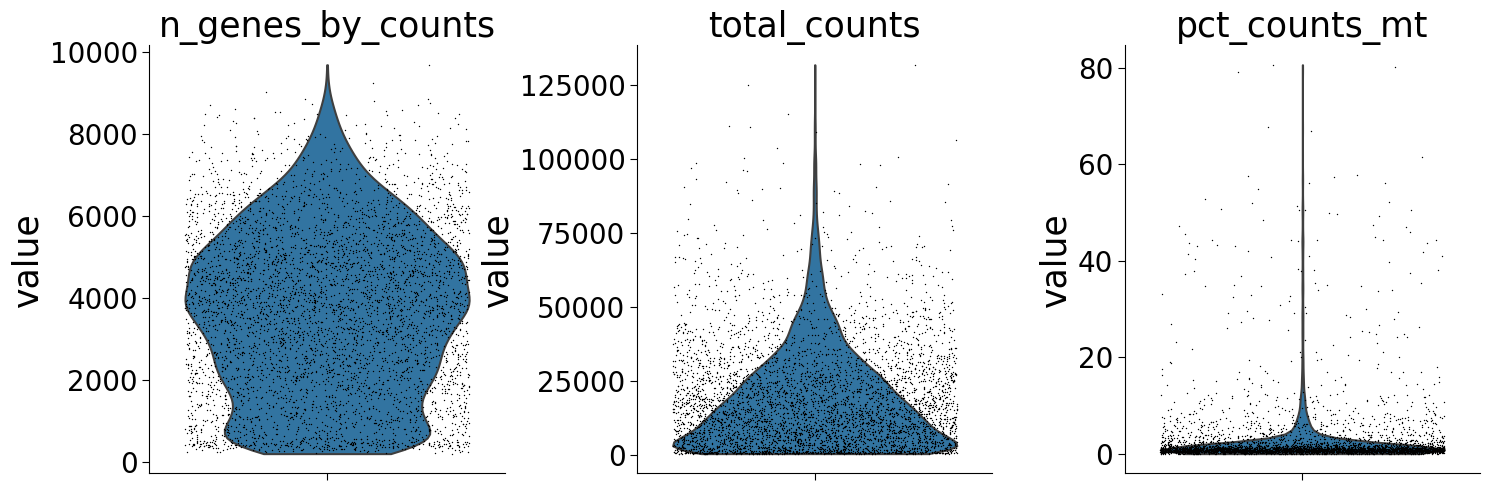

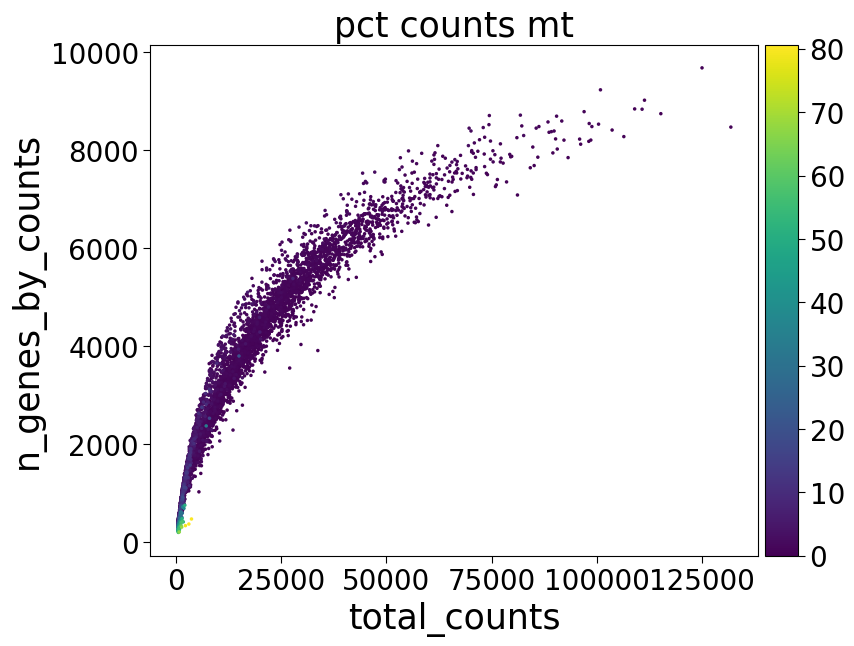

##### Lane: Lane9 #####


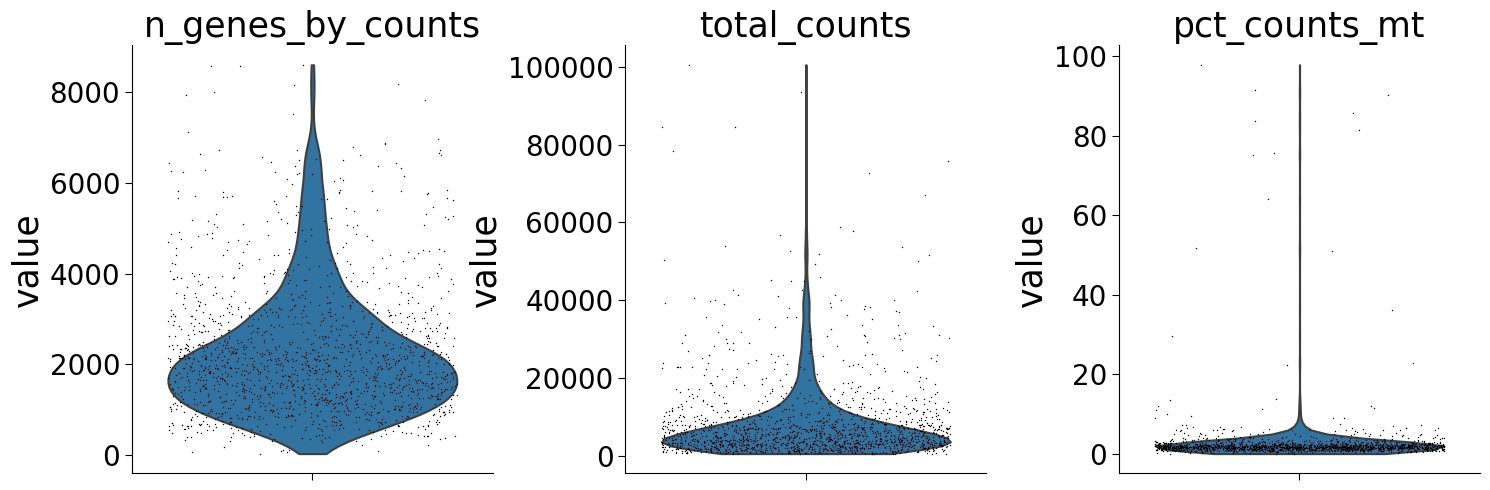

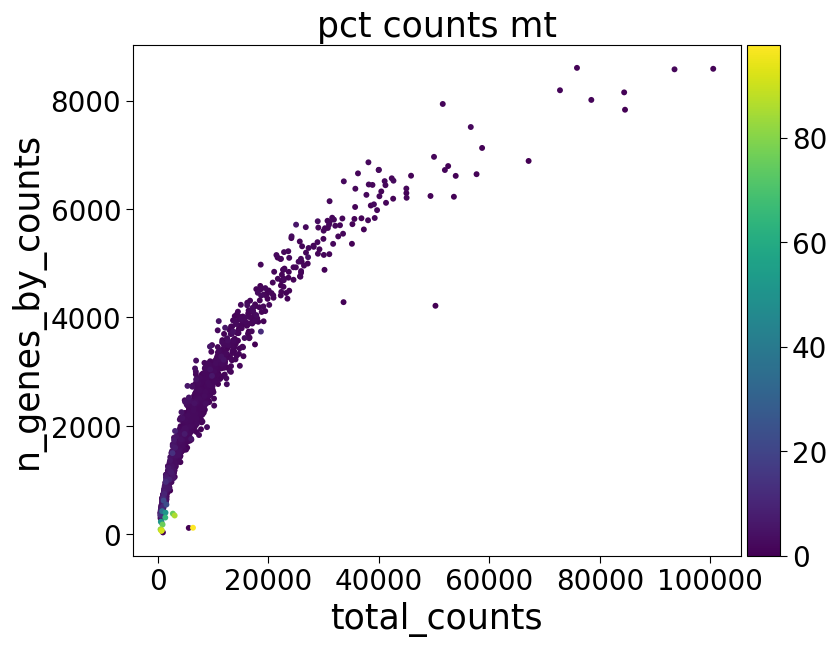

##### Lane: Lane10 #####


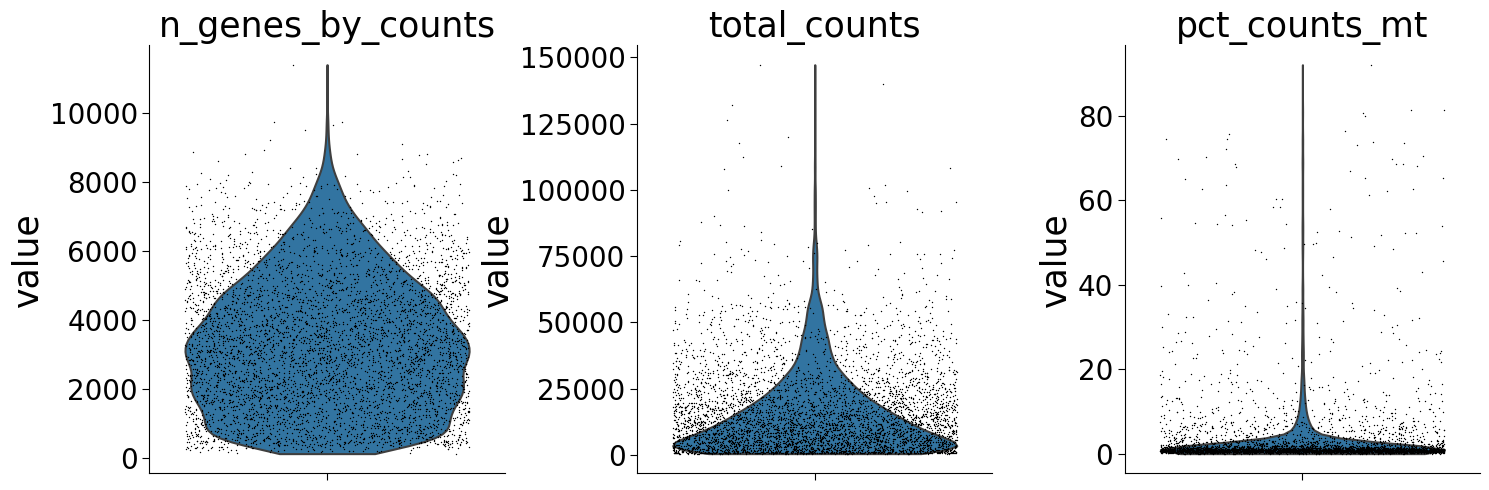

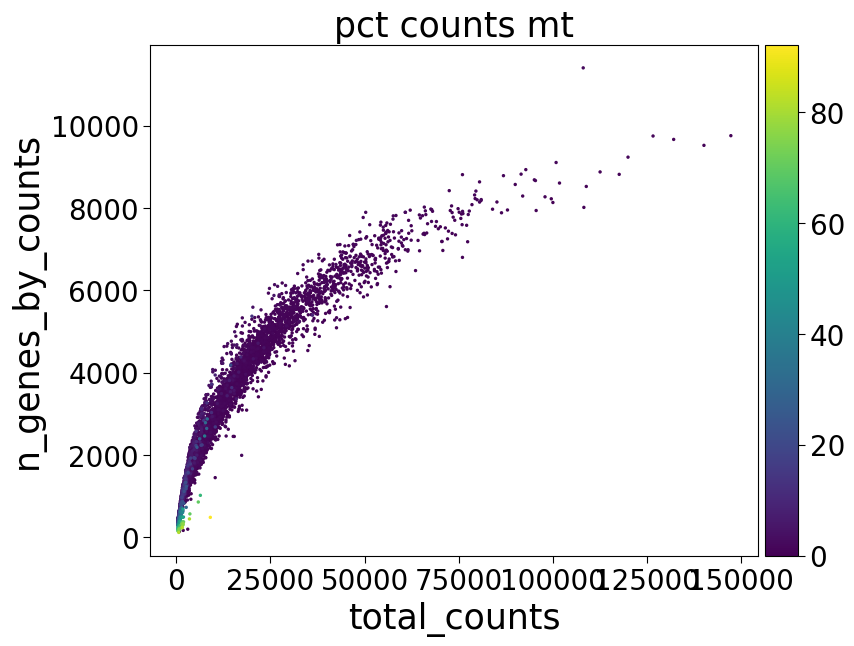

##### Lane: Lane11 #####


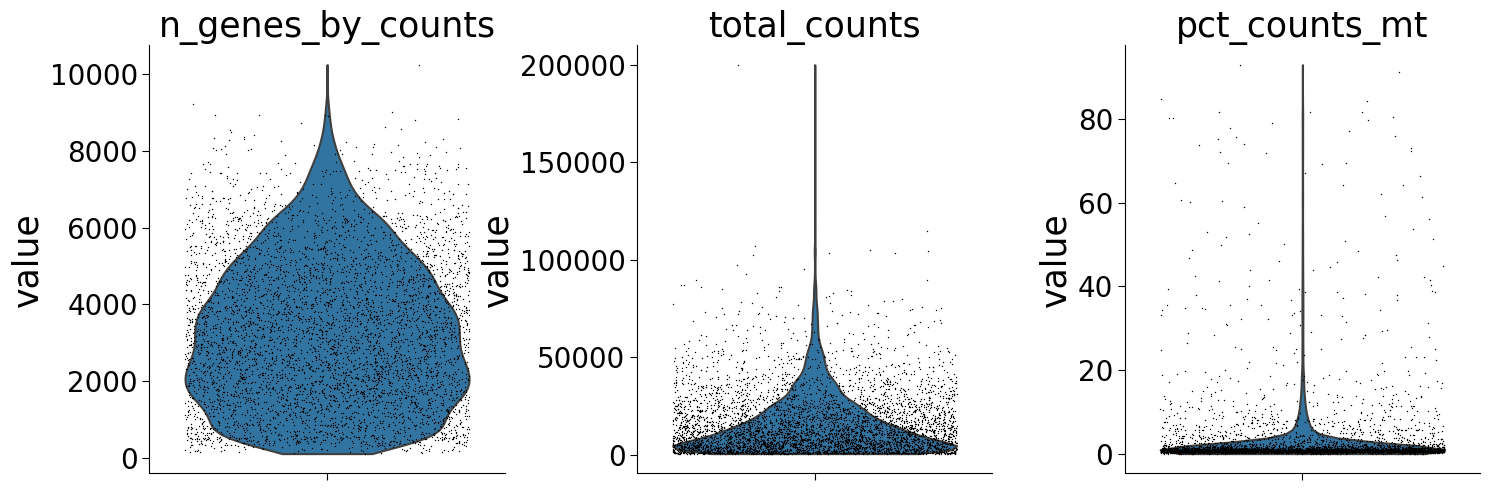

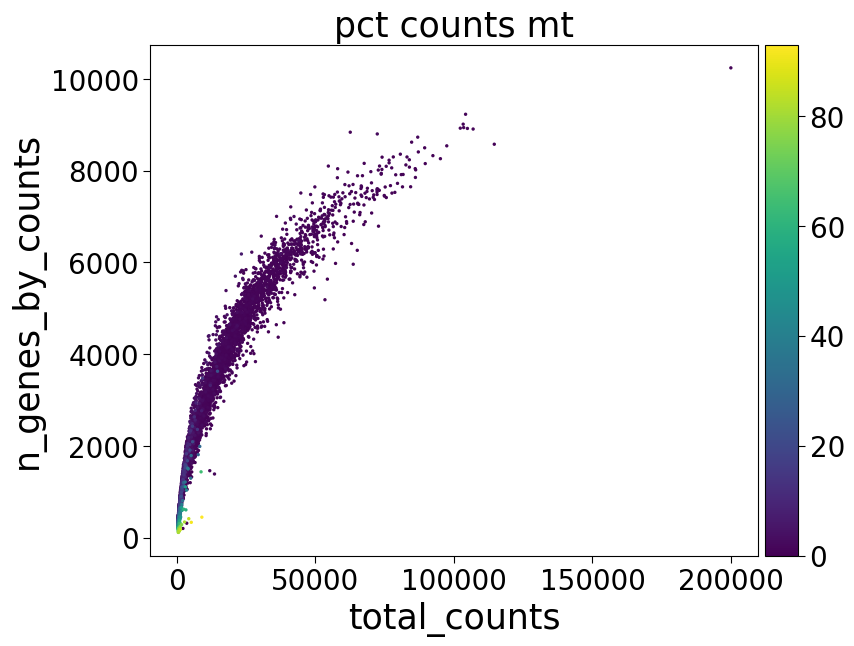

##### Lane: Lane12 #####


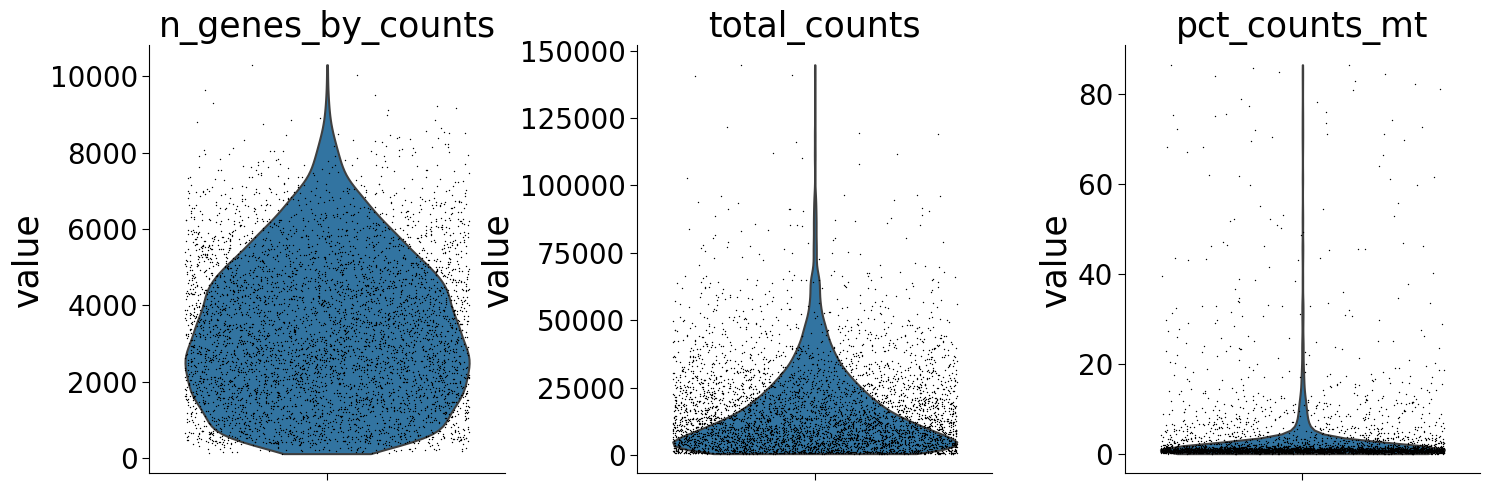

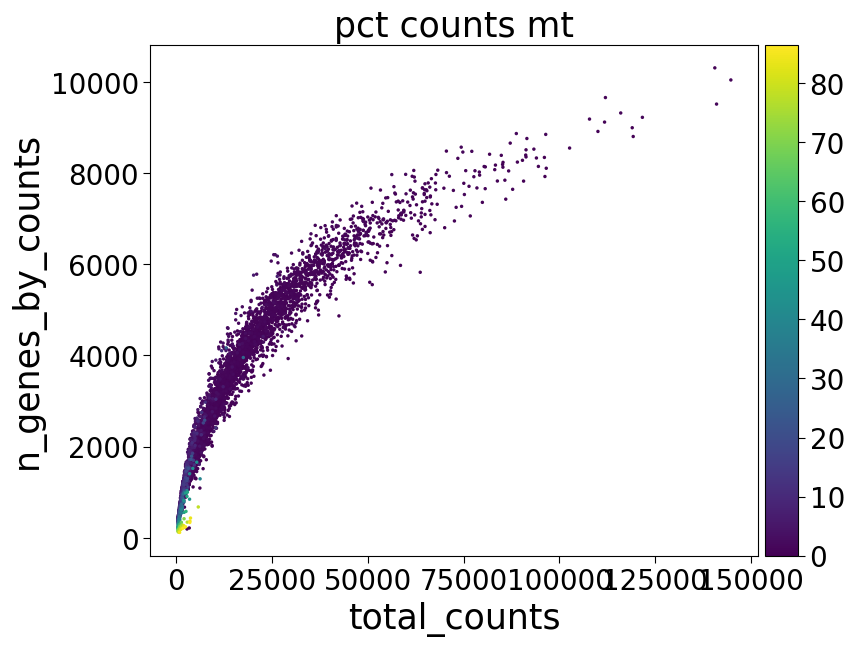

##### Lane: Lane13 #####


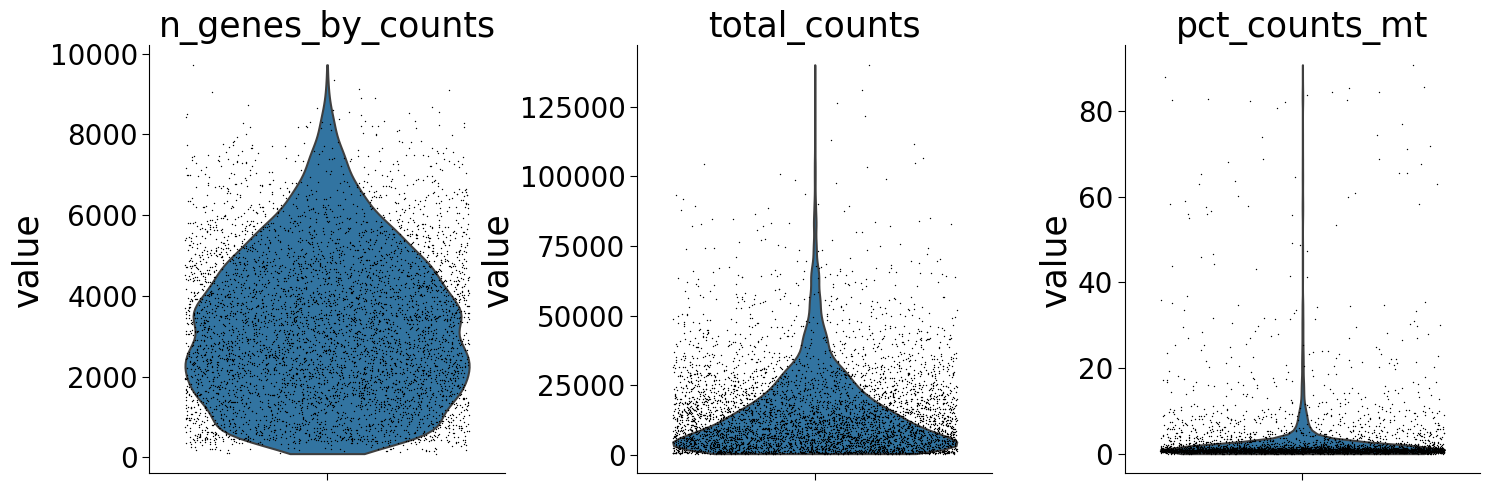

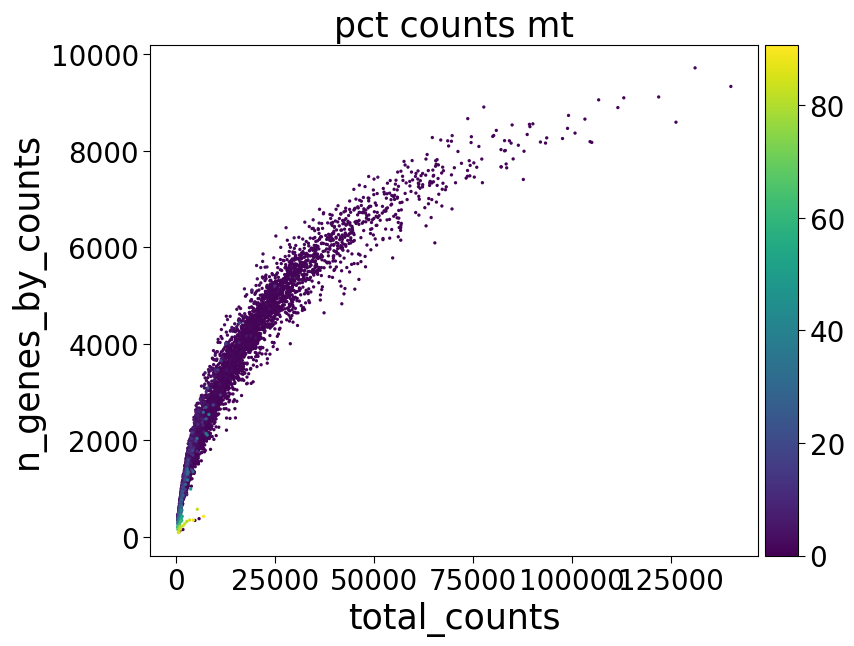

##### Lane: Lane14 #####


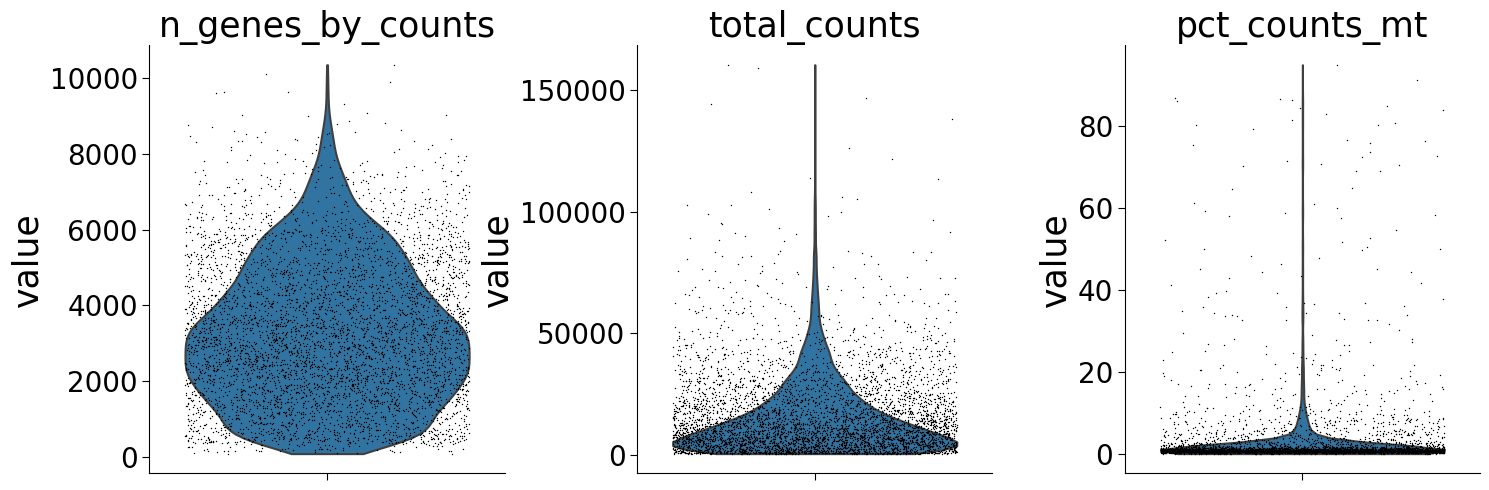

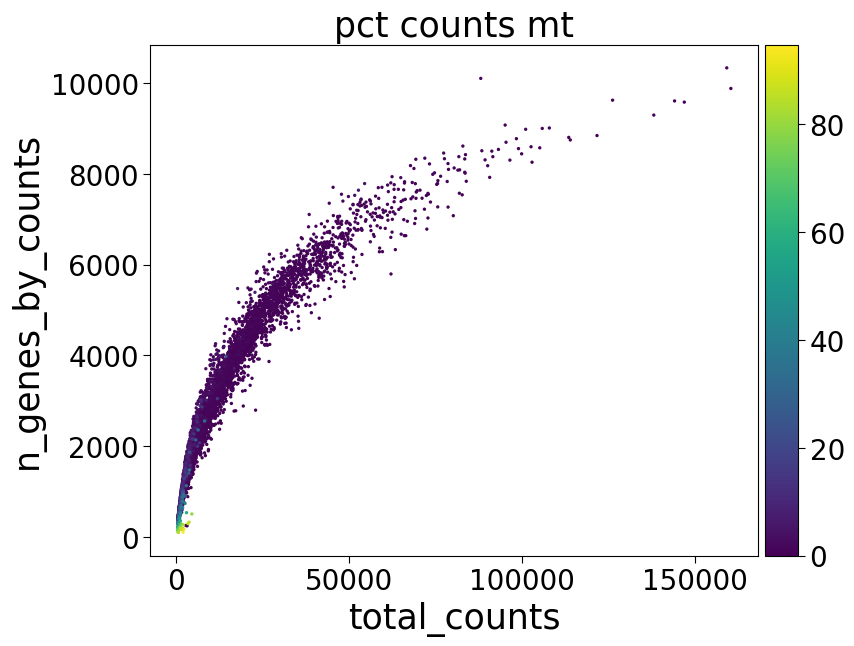

##### Lane: Lane15 #####


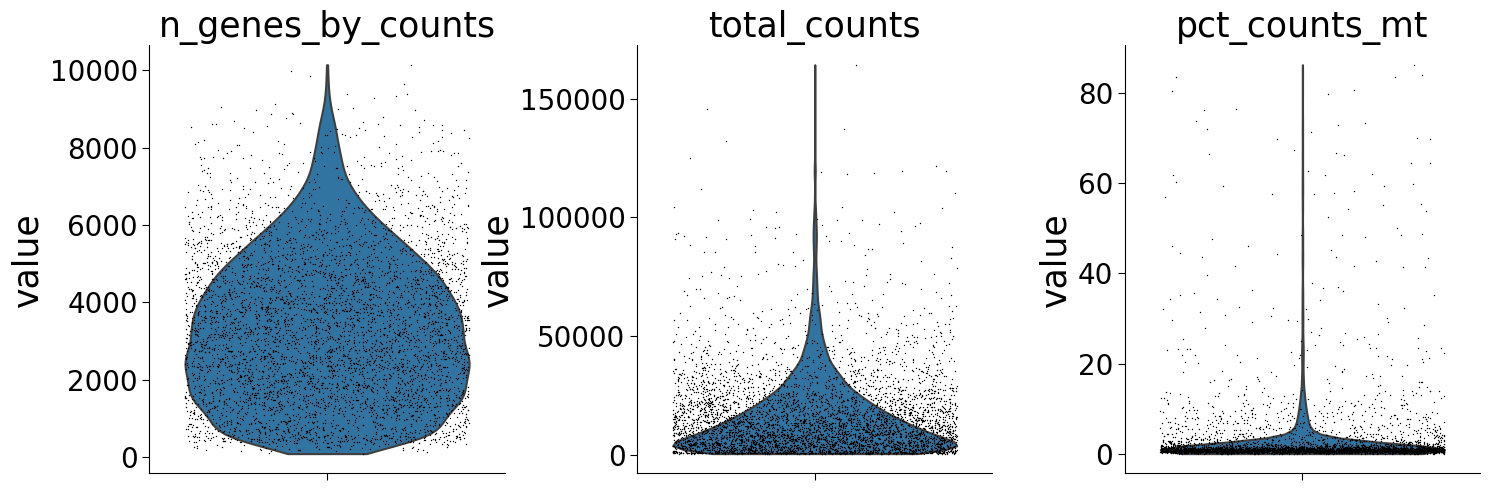

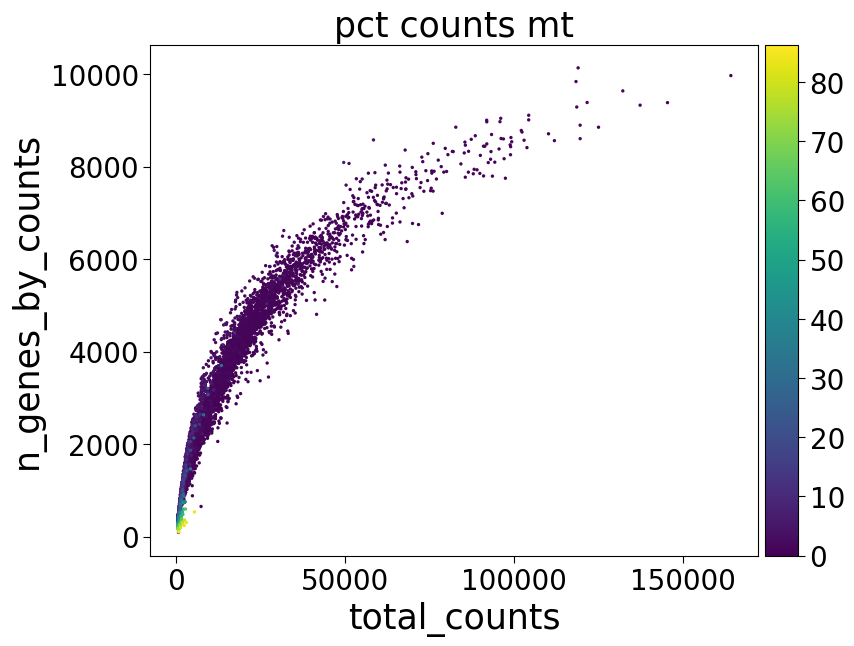

##### Lane: Lane16 #####


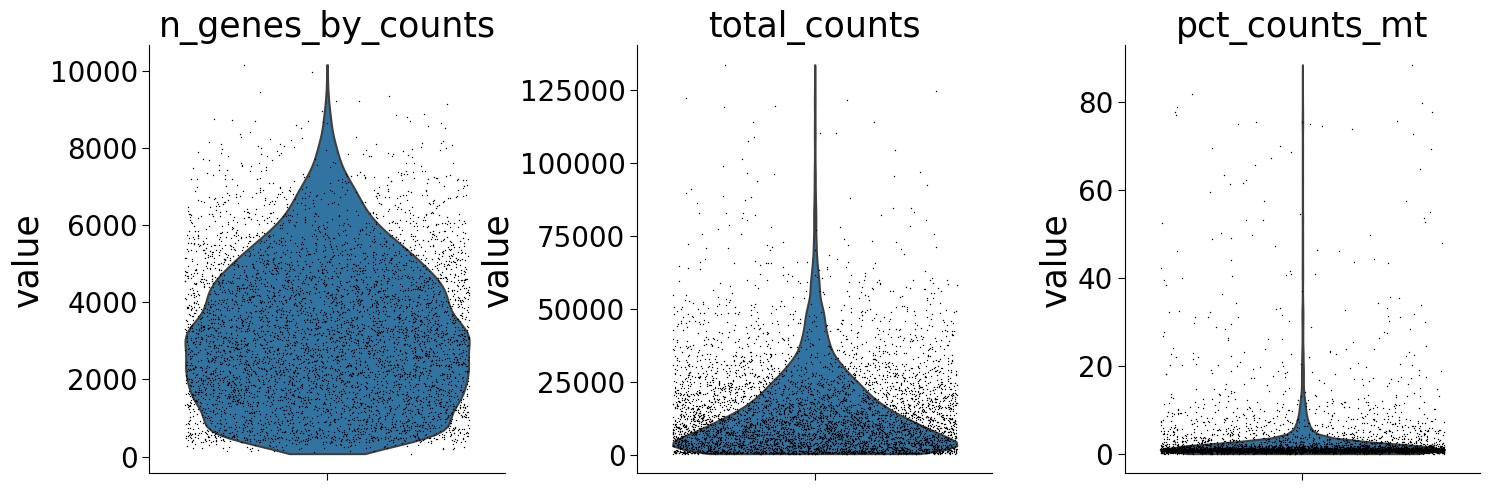

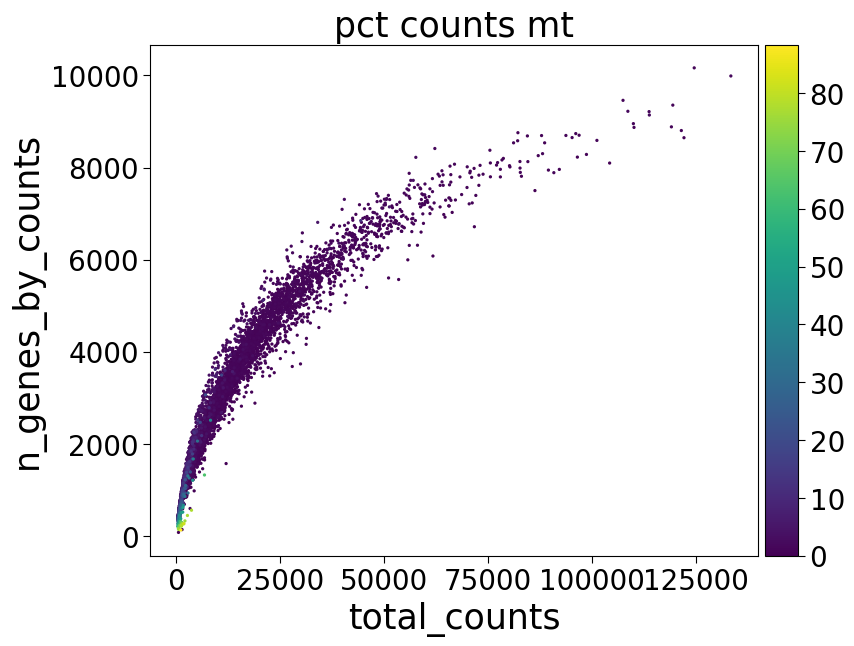

In [5]:
# 3) Run QC metrics (violin & scatter plots) for each lane
misc.plot_qc_metrics(adata_dict, qc_vars=["mt"])

In [6]:
# 3) Merge all AnnData objects into one
adata_list = list(adata_dict.values())

adata = adata_list[0].concatenate(
    *adata_list[1:], 
    batch_key="batch_lanes", 
    batch_categories=list(adata_dict.keys())
)

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  [AnnData(sparse.csr_matrix(a.shape), obs=a.obs) for a in all_adatas],


In [7]:
# Filter cells with less than 20% mitochondrial counts
adata = adata[adata.obs["percent_mito"] < 20, :]
    
sc.pp.filter_cells(adata, min_genes=400)
sc.pp.filter_genes(adata, min_cells=10)

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:140: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['n_genes'] = number


In [8]:
adata = misc.remove_TCR_genes(adata)

In [9]:
adata.obs = adata.obs[['lane', 'percent_mito']]
adata.var = adata.var[['gene_ids', 'feature_types']]

In [10]:
adata.obs_names = [e.split('-')[0] + '-1' for e in adata.obs_names]

In [11]:
adata.write_h5ad('/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/01_combined.h5ad')

# Adding Metadata Variables

In [12]:
adata = sc.read_h5ad('/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/01_combined.h5ad')

In [13]:
adata

AnnData object with n_obs × n_vars = 66499 × 22603
    obs: 'lane', 'percent_mito'
    var: 'gene_ids', 'feature_types'

In [14]:
adata.obs

,lane,percent_mito
lane1_AAACCTGCAGGGTTAG-1,lane1,1.395260
lane1_AAACCTGCAGTATGCT-1,lane1,1.446074
lane1_AAACCTGTCACAACGT-1,lane1,0.952633
lane1_AAACCTGTCCATTCTA-1,lane1,6.515838
lane1_AAACCTGTCGCTGATA-1,lane1,1.055737
...,...,...
lane16_TTTGTCACAGGAATGC-1,lane16,0.395994
lane16_TTTGTCACAGTGACAG-1,lane16,0.562588
lane16_TTTGTCAGTATTCGTG-1,lane16,0.758447
lane16_TTTGTCAGTCTCCACT-1,lane16,2.193606


## Mouse/Hashtag/Condition/Location

In [15]:
import os
import pandas as pd

# Directory where the metadata CSV files are saved
metadata_directory = "/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/hashtag_metadata"

# Initialize a dictionary to store the metadata DataFrames
metadata_dfs = {}

# Loop through each file in the directory and read it into a DataFrame
for i in range(1, 17):
    file_path = os.path.join(metadata_directory, f"lane{i}_metadata.csv")
    metadata_dfs[f"lane{i}"] = pd.read_csv(file_path, index_col=0)

# Concatenate metadata DataFrames into one DataFrame
metadata_combined = pd.concat(metadata_dfs.values(), keys=metadata_dfs.keys())

# Reset the index and reformat it
metadata_combined = metadata_combined.reset_index()
metadata_combined.index = "lane" + metadata_combined['level_0'].apply(lambda e: e[4:]) + "_" + metadata_combined['level_1'].astype(str)
metadata_combined = metadata_combined.drop(columns=['level_0', 'level_1'])

In [16]:
adata.obs

,lane,percent_mito
lane1_AAACCTGCAGGGTTAG-1,lane1,1.395260
lane1_AAACCTGCAGTATGCT-1,lane1,1.446074
lane1_AAACCTGTCACAACGT-1,lane1,0.952633
lane1_AAACCTGTCCATTCTA-1,lane1,6.515838
lane1_AAACCTGTCGCTGATA-1,lane1,1.055737
...,...,...
lane16_TTTGTCACAGGAATGC-1,lane16,0.395994
lane16_TTTGTCACAGTGACAG-1,lane16,0.562588
lane16_TTTGTCAGTATTCGTG-1,lane16,0.758447
lane16_TTTGTCAGTCTCCACT-1,lane16,2.193606


In [18]:
len(set(adata.obs_names).intersection(set(metadata_combined.index)))

66499

In [19]:
adata.obs = adata.obs.join(metadata_combined[['HTO_classification.global', 'HTO_maxID']], how='left')

In [20]:
adata = adata[adata.obs['HTO_classification.global'] == 'Singlet']

adata.obs.rename(columns={'HTO_maxID':'hashtag'}, inplace=True)

In [21]:
adata.obs.drop(columns=['HTO_classification.global'], inplace=True)

In [22]:
hashtag_to_condition = {
    1: "PD-1",
    2: "PD-1",
    3: "Isotype",
    4: "Isotype",
    5: "Isotype",
    6: "PD-1",
    7: "Isotype",
    8: "Isotype",
    9: "Isotype",
    10: "PD-1",
    11: "Isotype",
    12: "Isotype",
    13: "Isotype",
    14: "PD-1",
    15: "PD-1",
    16: "PD-1",
    17: "PD-1",
    18: "Isotype",
    19: "PD-1",
    20: "Isotype",
    21: "PD-1",
    22: "PD-1",
    23: "PD-1",
    24: "PD-1"
}

lane_location_dict = {
    1 : "Lymph Nodes",
    9: "Lymph Nodes",
    2: "Tumor",
    3: "Tumor",
    4: "Tumor",
    5: "Tumor",
    6: "Tumor",
    7: "Tumor",
    8: "Tumor",
    10: "Tumor",
    11: "Tumor",
    12: "Tumor",
    13: "Tumor",
    14: "Tumor",
    15: "Tumor",
    16: "Tumor"
}

In [23]:
import pandas as pd

# Assuming adata is your AnnData object

# Extracting the numeric part of the hashtag to match with hashtag_to_condition
adata.obs['hashtag_number'] = adata.obs['hashtag'].str.extract('(\d+)').astype(int)

# Mapping the condition based on the hashtag number
adata.obs['condition'] = adata.obs['hashtag_number'].map(hashtag_to_condition)

# Extracting the numeric part of the lane to match with lane_location_dict
adata.obs['lane_number'] = adata.obs['lane'].str.extract('(\d+)').astype(int)

# Mapping the location based on the lane number
adata.obs['location'] = adata.obs['lane_number'].map(lane_location_dict)

# Dropping the temporary columns used for mapping
adata.obs.drop(columns=['hashtag_number', 'lane_number'], inplace=True)

In [24]:
adata.obs['mouse'] = adata.obs['hashtag']

## all_constructs_str

In [25]:
reload(clonal_processing)

lane_info = []
for i in range(1, 17):
    lane_info.append({
        'lane_id': f'lane{i}',
        'assigned_bam_file': f"/Genomics/pritykinlab/share/perturbseq/fromMarc/new_data/trim28_setdb1_data/results/alignment/lane{i}/assigned_sorted.bam",
        'umi_file': f"/Genomics/pritykinlab/share/perturbseq/fromMarc/new_data/trim28_setdb1_data/results/pycashier_umi/lane{i}/output/pipeline/lane{i}.q30.barcodes.tsv"
    })

guide_seq_csv = "/Genomics/pritykinlab/share/perturbseq/fromMarc/new_data/trim28_setdb1_data/reference_genome/guide_seq.csv"
output_all_path = "/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/CBC_guide_umi.tsv"

guide_umi_df = clonal_processing.build_guide_umi_df_for_all_lanes(
    lane_info=lane_info,
    guide_seq_csv=guide_seq_csv,
    output_all_path=output_all_path,
    overwrite=False
)

cbc_construct_mtx = clonal_processing.pivot_CBC_construct_mtx(
    guide_umi_df,
    min_count=3,    # adjust threshold as desired
    binarize=False
)

clonal_processing.annotate_adata_with_clones(
    adata,
    cbc_construct_mtx
)

# Construct Filtering

In [26]:
adata = clonal_processing.run_doublet_constrct_calling(adata)

# Get some useful columns

In [27]:
def get_cat_num_constructs(e):
    if e == 1:
        return "One"
    elif e > 1:
        return "More than One"
    else:
        return "Zero"
adata.obs['cat_num_constructs'] = adata.obs['num_constructs'].apply(get_cat_num_constructs)

def assign_clone(row):
    if row['all_constructs_str'] == '':
        return ''
    else:
        return f"{row['mouse']}|{row['all_constructs_str']}"
    
# Helper function to process guides and perturbations
def process_constructs(row):
    value = row['all_constructs_str']
    guides = value.split('___')
    processed_guides = []
    processed_perturbations = []
    for guide in guides:
        split_guide = guide.split('__')
        processed_guides.append(split_guide[0])
        if guide.startswith("ONE_INTERGENIC_SITE_") or guide.startswith("NO_SITE_"):
            processed_perturbations.append("NT")
        else:
            gene = split_guide[0].split('-')[0]
            processed_perturbations.append(gene)
    return "__".join(processed_guides), "__".join(processed_perturbations)

# Apply the function row-wise and create new columns
adata.obs[['guide', 'perturbation']] = adata.obs.apply(process_constructs, axis=1, result_type='expand')

# Apply the function across the rows
adata.obs['clone'] = adata.obs.apply(assign_clone, axis=1)

In [28]:
from collections import OrderedDict

guide_new_label_mapping = OrderedDict([
    ('ONE_INTERGENIC_SITE_18', 'INTERGENIC-5'),
    ('NO_SITE_26', 'NO_SITE-1'),
    ('NO_SITE_80', 'NO_SITE-2'),
    ('NO_SITE_223', 'NO_SITE-3'),
    ('NO_SITE_913', 'NO_SITE-4'),
    ('NO_SITE_738', 'NO_SITE-5'),
    ('ONE_INTERGENIC_SITE_1', 'INTERGENIC-1'),
    ('ONE_INTERGENIC_SITE_21', 'INTERGENIC-2'),
    ('ONE_INTERGENIC_SITE_5', 'INTERGENIC-3'),
    ('ONE_INTERGENIC_SITE_24', 'INTERGENIC-4'),
    ('NO_SITE_5', 'NO_SITE-6'),
    ('NO_SITE_3', 'NO_SITE-7'),
    ('NO_SITE_1', 'NO_SITE-8'),
    ('NO_SITE_2', 'NO_SITE-9'),
    ('NO_SITE_4', 'NO_SITE-10'),
    ('NO_SITE_6', 'NO_SITE-11'),
])

columns_to_change = ['all_constructs_str', 'guide']
for col in columns_to_change:
    for key, value in guide_new_label_mapping.items():
        adata.obs[col] = adata.obs[col].apply(lambda e: e.replace(key, value))

In [29]:
adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/02_LP.h5ad")